In [22]:
# --- 1. Setup and Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
import pickle
import os

In [23]:
# --- 2. Configuration ---
# !!! IMPORTANT: Replace this path with your exact file path !!!
FILE_PATH = '../data/car_sales_preprocessed_2.csv'
TARGET_COLUMN = 'Body Type_LE'

# Visualization setting for notebooks (run this in a separate cell if needed)
# %matplotlib inline

In [24]:
%matplotlib inline

In [25]:
# --- 3. Data Loading (Uncomment this section for real data) ---
try:
    # Attempt to load the actual data
    df = pd.read_csv(FILE_PATH)
    print(f"Data loaded successfully from: {FILE_PATH}")
except FileNotFoundError:
    print(f"ERROR: File not found at {FILE_PATH}.")
    print("Generating synthetic data for demonstration structure.")
    
    # --- Synthetic Data Generation (Fallback) ---
    def generate_synthetic_data():
        headers = [
            'quarter','Brand_LE','Model_LE','Body Type_LE','Year_2022','Year_2023',
            'TU_وحدة مرور القاهرة الجديدة', 'TU_وحدة مرور طنطا', 'TU_وحدة مرور كوم حماده',
            'TU_وحدة مرور شبين الكوم', 'Gov_القاهرة', 'Gov_الاسكندرية'
        ]
        data_size = 1000
        data = {
            'quarter': np.random.randint(1, 5, size=data_size),
            'Brand_LE': np.random.randint(1, 100, size=data_size),
            'Model_LE': np.random.randint(100, 500, size=data_size),
            'Body Type_LE': np.random.randint(0, 9, size=data_size) # 9 classes
        }
        for col in headers[6:]: # TU_ and Gov_ columns
            data[col] = np.random.choice([False, True], size=data_size, p=[0.85, 0.15])
        return pd.DataFrame(data).drop(columns=['Gov_القاهرة', 'Gov_الاسكندرية'])

   #df = generate_synthetic_data()

print("\n--- Initial Data Check ---")
print(f"Dataset Shape: {df.shape}")

# Define Target and Features (excluding all Gov_ columns)
X = df.drop(columns=[col for col in df.columns if col.startswith('Gov_') or col == TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Select only base features and TU_ features
tu_columns = [col for col in X.columns if col.startswith('TU_')]
base_features = ['quarter', 'Brand_LE', 'Model_LE', 'Year_2022', 'Year_2023']
selected_features = [f for f in base_features + tu_columns if f in X.columns]
X = X[selected_features]

# Convert all boolean columns (from one-hot encoding) to integers (0 and 1)
boolean_cols = X.select_dtypes(include=['bool']).columns
X[boolean_cols] = X[boolean_cols].astype(int)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"\nTraining set size: {X_train.shape[0]} samples")
print(f"Selected features count: {X_train.shape[1]}")

Data loaded successfully from: ../data/car_sales_preprocessed_2.csv

--- Initial Data Check ---
Dataset Shape: (761973, 236)

Training set size: 571479 samples
Selected features count: 209


In [26]:
# --- 4. Model Training ---
print("\n--- Training Random Forest Classifier with TU Features... ---")

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

print("Training complete.")

# Make predictions on the test set
y_pred = model.predict(X_test)


--- Training Random Forest Classifier with TU Features... ---
Training complete.



🎯 Overall Model Performance (Macro Averaged)
Accuracy:  0.9965
Precision: 0.8816
Recall:    0.8756
F1-Score:  0.8786
--------------------------------------------------

--- Confusion Matrix Visualization ---


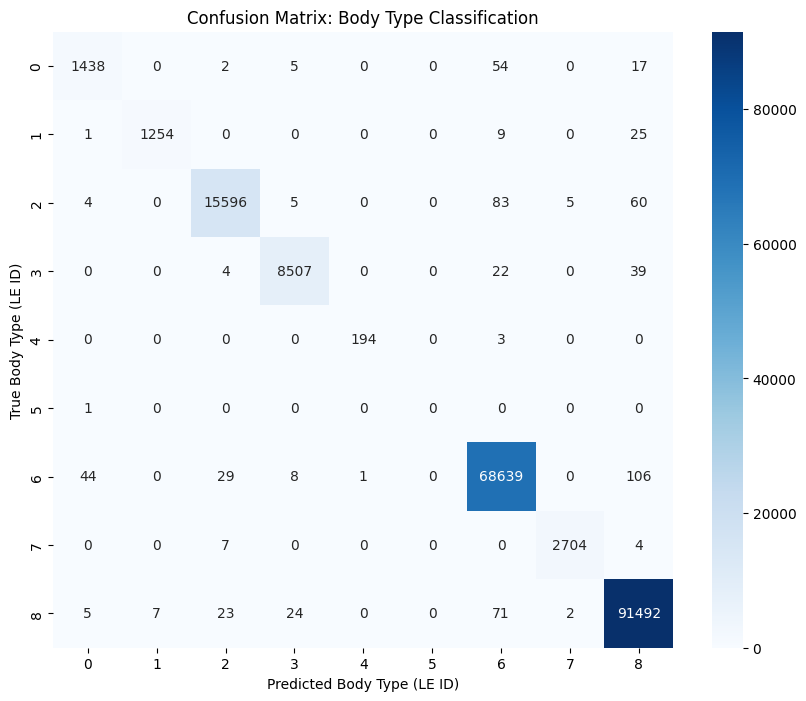

In [27]:
# --- 5. Essential Model Evaluation ---

# Ensure predictions and true values are simple arrays
y_test_clean = np.asarray(y_test)
y_pred_clean = np.asarray(y_pred)
ALL_LABELS = model.classes_

# 1. Calculate Overall Metrics (Macro Average)
# We specify ALL_LABELS to handle classes missed in prediction (like class 5 in previous run)
accuracy = accuracy_score(y_test_clean, y_pred_clean)
precision_macro = precision_score(y_test_clean, y_pred_clean, average='macro', zero_division=0, labels=ALL_LABELS)
recall_macro = recall_score(y_test_clean, y_pred_clean, average='macro', zero_division=0, labels=ALL_LABELS)
f1_macro = f1_score(y_test_clean, y_pred_clean, average='macro', zero_division=0, labels=ALL_LABELS)

print("\n" + "="*50)
print("🎯 Overall Model Performance (Macro Averaged)")
print("="*50)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision_macro:.4f}")
print(f"Recall:    {recall_macro:.4f}")
print(f"F1-Score:  {f1_macro:.4f}")
print("-" * 50)


# 2. Confusion Matrix Visualization
print("\n--- Confusion Matrix Visualization ---")

if len(ALL_LABELS) > 1:
    plt.figure(figsize=(10, 8))
    
    # Calculate the Confusion Matrix
    cm = confusion_matrix(y_test_clean, y_pred_clean, labels=ALL_LABELS)
    
    class_labels_str = [str(c) for c in ALL_LABELS]
    
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        xticklabels=class_labels_str, 
        yticklabels=class_labels_str
    ) 
    
    plt.title('Confusion Matrix: Body Type Classification')
    plt.xlabel('Predicted Body Type (LE ID)')
    plt.ylabel('True Body Type (LE ID)')
    plt.show()
else:
    print("Cannot display Confusion Matrix: Only one unique class found in target data.")


🏗️  TOP 10 TUs: ROUGHER ROAD / UTILITY VEHICLE PRIORITY (Highest Feature Importance)
These TUs show the most distinct vehicle mix, suggesting a high preference for RUGGED vehicles (SUVs/Pickups).
Action: These TUs should be prioritized for robust road maintenance.
--------------------------------------------------------------------------------
 Rank          Traffic Unit Column Importance Score
    1        TU_وحدة مصر الجديــدة           0.0006
    2          TU_وحدة مرور الدقـي           0.0006
    3        TU_وحدة مرور العجـوزة           0.0005
    4          TU_وحده مرور النزهه           0.0005
    5 TU_وحدة مرور القاهرة الجديدة           0.0005
    6       TU_وحدة مرور مدينة نصر           0.0005
    7        TU_وحدة مرور المنصورة           0.0004
    8      TU_وحدة القوات المسلحـة           0.0004
    9      TU_وحدة مرور الشيخ زايد           0.0004
   10        TU_وحدة مرور 6 اكتوبر           0.0004

🛣️ TOP 10 TUs: SMOOTHER ROAD / SEDAN PRIORITY (Lowest Feature Importance)
These 

/tmp/ipykernel_11727/875593501.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


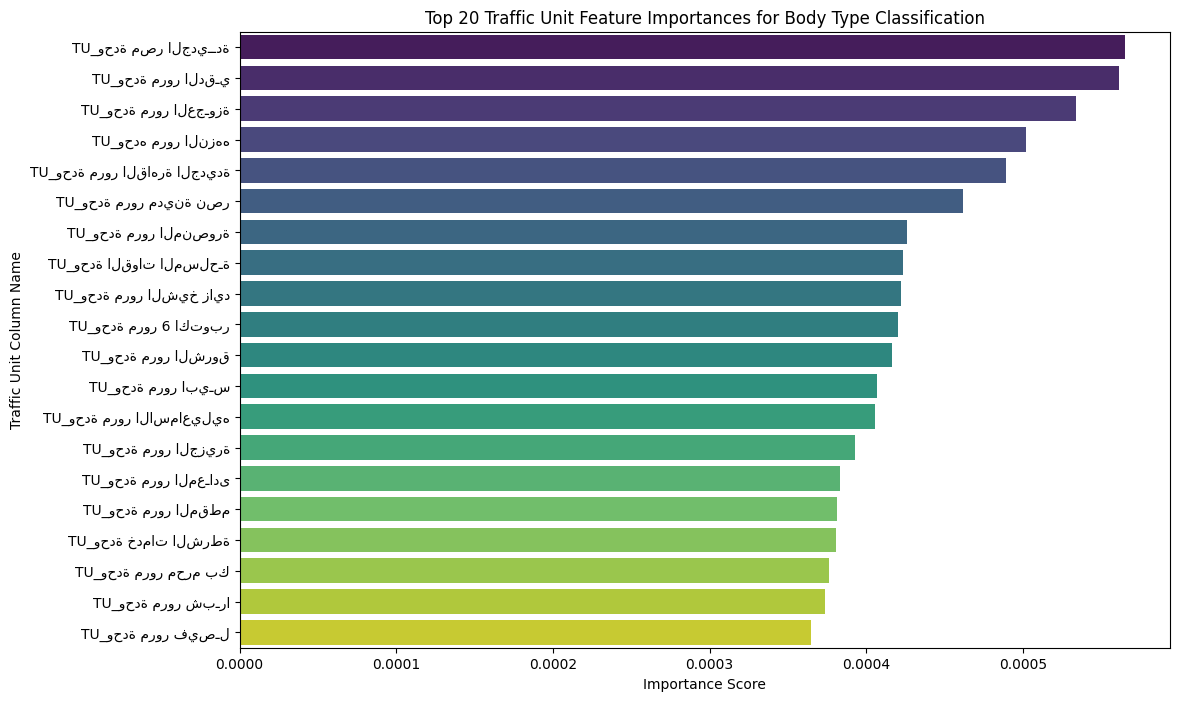

In [28]:
# --- 6. Feature Importance and Top 10 TU Categorization (Simplified) ---

# Get all feature importances from the trained model
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns)

# Filter only the Traffic Unit features
tu_importances = feature_importances[feature_importances.index.str.startswith('TU_')]
tu_importances_sorted = tu_importances.sort_values(ascending=False)

# --- Determine the Top 10 and Bottom 10 TUs ---
TOP_N = 10
BOTTOM_N = 10

# 1. Top 10 most distinct TUs (likely Rougher Roads / Utility Vehicles)
rough_road_tugs = tu_importances_sorted.head(TOP_N)

# 2. Bottom 10 least distinct TUs (likely Smoother Roads / Sedan Preference)
smooth_road_tugs = tu_importances_sorted.tail(BOTTOM_N)

# --- Output 1: Rougher Roads / Utility Vehicle Preference (Top 10) ---

rough_data = []
for i, (tu_key, importance) in enumerate(rough_road_tugs.items()):
    rough_data.append({
        'Rank': i + 1,
        'Traffic Unit Column': tu_key,
        'Importance Score': f"{importance:.4f}"
    })

rough_df = pd.DataFrame(rough_data)

print("\n" + "="*80)
print("🏗️  TOP 10 TUs: ROUGHER ROAD / UTILITY VEHICLE PRIORITY (Highest Feature Importance)")
print("="*80)
print("These TUs show the most distinct vehicle mix, suggesting a high preference for RUGGED vehicles (SUVs/Pickups).")
print("Action: These TUs should be prioritized for robust road maintenance.")
print("-" * 80)

# FIX: Use .to_string() instead of .to_markdown() to avoid the 'tabulate' dependency
print(rough_df.to_string(index=False))


# --- Output 2: Smoother Roads / Sedan Preference (Bottom 10) ---

smooth_data = []
# Reverse the ranking for "Smoother" list (Rank 1 is the least distinct TU)
for i, (tu_key, importance) in enumerate(smooth_road_tugs.sort_values(ascending=True).items()):
    smooth_data.append({
        'Rank': i + 1,
        'Traffic Unit Column': tu_key,
        'Importance Score': f"{importance:.4f}"
    })

smooth_df = pd.DataFrame(smooth_data)

print("\n" + "="*80)
print("🛣️ TOP 10 TUs: SMOOTHER ROAD / SEDAN PRIORITY (Lowest Feature Importance)")
print("="*80)
print("These TUs show the least distinct vehicle mix, suggesting a high preference for COMPACT vehicles (Sedans/Hatchbacks).")
print("Action: These TUs should be prioritized for flow, congestion, and parking solutions.")
print("-" * 80)

# FIX: Use .to_string() instead of .to_markdown()
print(smooth_df.to_string(index=False))

# --- Visualization Fix: Top 20 TUs ---

print("\n--- Final Visualization: Top 20 Traffic Unit Feature Importance ---")

# 1. Select the top 20 items (values and index/names) from the sorted Series
top_20_tu = tu_importances_sorted.head(20)

# 2. Check if we have enough data to plot
if len(top_20_tu) == 0:
    print("WARNING: No Traffic Unit features found with non-zero importance to plot.")
else:
    plt.figure(figsize=(12, 8))
    
    # Use the .values (importance scores) and .index (TU names) from the new Series
    sns.barplot(
        x=top_20_tu.values, 
        y=top_20_tu.index, 
        palette='viridis'
    )
    
    plt.title('Top 20 Traffic Unit Feature Importances for Body Type Classification')
    plt.xlabel('Importance Score')
    plt.ylabel('Traffic Unit Column Name')
    plt.show() # Ensure the plot is displayed

In [29]:
# --- 7. Model Saving ---
model_filename = '../models/random_forest_tu_classifier.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(model, file)
    
print(f"\nSuccessfully saved the trained Random Forest model to: {model_filename}")


Successfully saved the trained Random Forest model to: random_forest_tu_classifier.pkl
